# Experiment 1. Предсказание результатов матчей EPL

## 1. Постановка задачи

**Цель эксперимента** — определить, насколько результаты предыдущих матчей команд помогают предсказывать исход следующего матча.

Рассматривается задача многоклассовой классификации с тремя классами:
- `H` — победа домашней команды;
- `D` — ничья;
- `A` — победа гостевой команды.

В качестве признаков используются количество побед, ничьих и поражений обеих команд за последние N матчей.


## 2. Описание данных

Используются данные английской Премьер-лиги (EPL) за 10 сезонов — с 2015/16 по 2024/25. Источник — Football-Data.co.uk. Исходный набор содержит 3800 матчей.

Для каждого матча формируются шесть признаков: количество побед, ничьих и поражений домашней и гостевой команд за последние N игр.

Целевая переменная `target` принимает значения `H`, `D` и `A`. Сравниваются пять вариантов исторического окна: N = 3, 5, 10, 15 и 20.


## 3. Импорт библиотек


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


## 4. Загрузка данных

Загрузим пять подготовленных датасетов. Каждый файл соответствует отдельному значению N.


In [2]:
DATA_DIR = Path("../data/processed")
n_values = [3, 5, 10, 15, 20]

datasets = {}

for n in n_values:
    file_path = DATA_DIR / f"dataset_n{n}.csv"
    datasets[n] = pd.read_csv(file_path, parse_dates=["Date"])


## 5. Первичный анализ данных

Проверим размеры датасетов, пропуски, дубликаты и распределение целевой переменной.


In [3]:
for n, df in datasets.items():
    print(f"\nN = {n}")
    print("Размер:", df.shape)
    print("Пропуски:", df.isna().sum().sum())
    print("Дубликаты:", df.duplicated(subset=["Date", "HomeTeam", "AwayTeam"]).sum())
    print("Распределение классов:")
    print(df["target"].value_counts())



N = 3
Размер: (3728, 10)
Пропуски: 0
Дубликаты: 0
Распределение классов:
target
H    1667
A    1199
D     862
Name: count, dtype: int64

N = 5
Размер: (3681, 10)
Пропуски: 0
Дубликаты: 0
Распределение классов:
target
H    1647
A    1184
D     850
Name: count, dtype: int64

N = 10
Размер: (3562, 10)
Пропуски: 0
Дубликаты: 0
Распределение классов:
target
H    1602
A    1139
D     821
Name: count, dtype: int64

N = 15
Размер: (3444, 10)
Пропуски: 0
Дубликаты: 0
Распределение классов:
target
H    1545
A    1110
D     789
Name: count, dtype: int64

N = 20
Размер: (3327, 10)
Пропуски: 0
Дубликаты: 0
Распределение классов:
target
H    1491
A    1073
D     763
Name: count, dtype: int64


### Распределение целевой переменной

Посмотрим, насколько часто встречается каждый из трёх исходов.


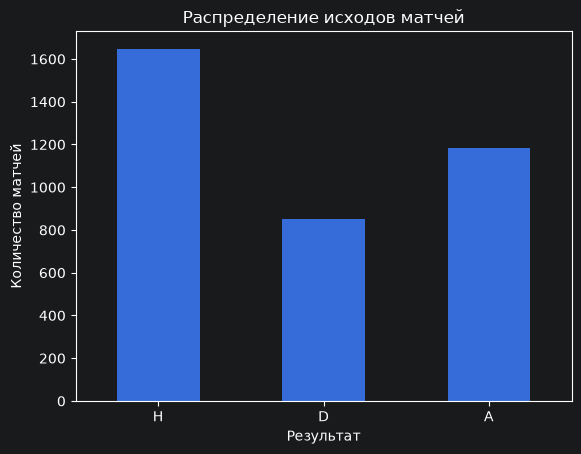

In [4]:
class_counts = datasets[5]["target"].value_counts().reindex(["H", "D", "A"])

class_counts.plot(kind="bar", rot=0)
plt.title("Распределение исходов матчей")
plt.xlabel("Результат")
plt.ylabel("Количество матчей")
plt.show()


## 6. Подготовка выборок

Разделим данные по времени, а не случайным образом:
- **Train:** матчи до 1 июля 2023 года;
- **Validation:** сезон 2023/24;
- **Test:** сезон 2024/25.

В модель передаются только шесть числовых признаков. Дата и названия команд используются для организации данных, но не являются признаками модели.


In [5]:
feature_columns = [
    "home_wins", "home_draws", "home_losses",
    "away_wins", "away_draws", "away_losses"
]

target_column = "target"

def split_data(df):
    train = df[df["Date"] < "2023-07-01"].copy()
    valid = df[
        (df["Date"] >= "2023-07-01") &
        (df["Date"] < "2024-07-01")
    ].copy()
    test = df[df["Date"] >= "2024-07-01"].copy()

    return train, valid, test

for n, df in datasets.items():
    train, valid, test = split_data(df)
    print(f"N = {n}: train={len(train)}, validation={len(valid)}, test={len(test)}")


N = 3: train=2974, validation=377, test=377
N = 5: train=2931, validation=375, test=375
N = 10: train=2822, validation=370, test=370
N = 15: train=2714, validation=365, test=365
N = 20: train=2607, validation=360, test=360


## 7. Базовая модель (Baseline)

Сначала построим простую модель, которая всегда предсказывает самый частый класс в обучающей выборке.

Это базовый уровень качества. Logistic Regression должна превзойти его, чтобы иметь практический смысл.


In [6]:
baseline_results = []

for n, df in datasets.items():
    train, valid, test = split_data(df)

    X_train = train[feature_columns]
    y_train = train[target_column]
    X_valid = valid[feature_columns]
    y_valid = valid[target_column]

    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X_train, y_train)

    predictions = baseline.predict(X_valid)

    baseline_results.append({
        "N": n,
        "Accuracy": accuracy_score(y_valid, predictions),
        "Macro F1": f1_score(y_valid, predictions, average="macro")
    })

baseline_results = pd.DataFrame(baseline_results)
baseline_results


,N,Accuracy,Macro F1
0,3,0.458886,0.209697
1,5,0.458667,0.209628
2,10,0.462162,0.210721
3,15,0.460274,0.210131
4,20,0.463889,0.211259


## 8. Обучение Logistic Regression

Обучим Logistic Regression для каждого значения N.

Перед моделью используем StandardScaler: он стандартизирует числовые признаки. Масштабирование и модель объединены в один Pipeline, чтобы преобразование обучалось только на тренировочных данных.


In [7]:
model_results = []
trained_models = {}

for n, df in datasets.items():
    train, valid, test = split_data(df)

    X_train = train[feature_columns]
    y_train = train[target_column]
    X_valid = valid[feature_columns]
    y_valid = valid[target_column]

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_valid)

    trained_models[n] = model

    model_results.append({
        "N": n,
        "Accuracy": accuracy_score(y_valid, predictions),
        "Macro F1": f1_score(y_valid, predictions, average="macro")
    })

model_results = pd.DataFrame(model_results)
model_results


,N,Accuracy,Macro F1
0,3,0.506631,0.358079
1,5,0.525333,0.370703
2,10,0.524324,0.379365
3,15,0.567123,0.415006
4,20,0.572222,0.417532


## 9. Сравнение моделей на Validation

Сравним Baseline и Logistic Regression по двум метрикам:
- **Accuracy** — доля правильных предсказаний;
- **Macro F1** — среднее значение F1 по трём классам, при этом каждый класс имеет одинаковый вес.

Значение N выбирается по результатам Validation. Тестовая выборка на этом этапе не используется для выбора модели.


In [8]:
comparison = model_results.merge(
    baseline_results,
    on="N",
    suffixes=("_Logistic", "_Baseline")
)

comparison


,N,Accuracy_Logistic,Macro F1_Logistic,Accuracy_Baseline,Macro F1_Baseline
0,3,0.506631,0.358079,0.458886,0.209697
1,5,0.525333,0.370703,0.458667,0.209628
2,10,0.524324,0.379365,0.462162,0.210721
3,15,0.567123,0.415006,0.460274,0.210131
4,20,0.572222,0.417532,0.463889,0.211259


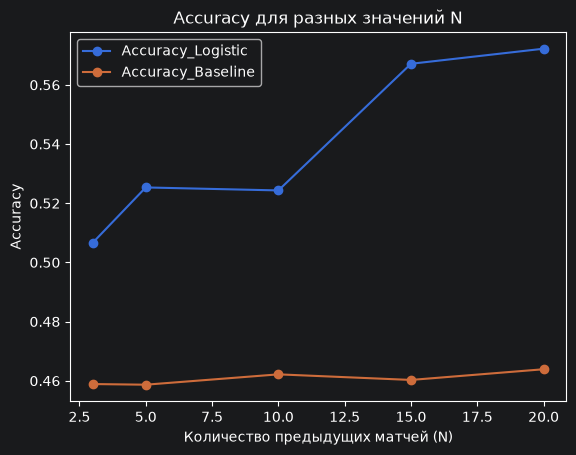

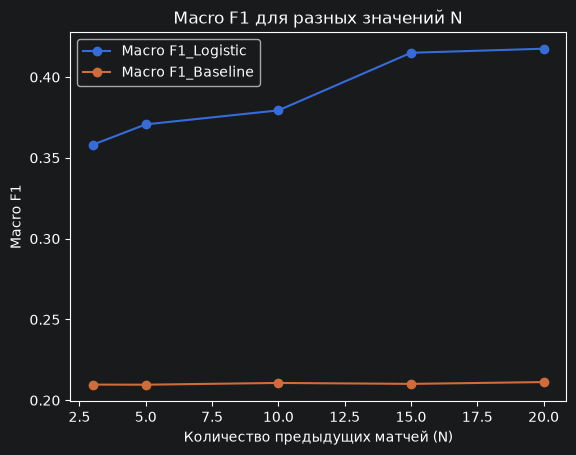

In [9]:
comparison.plot(
    x="N",
    y=["Accuracy_Logistic", "Accuracy_Baseline"],
    marker="o"
)
plt.title("Accuracy для разных значений N")
plt.xlabel("Количество предыдущих матчей (N)")
plt.ylabel("Accuracy")
plt.show()

comparison.plot(
    x="N",
    y=["Macro F1_Logistic", "Macro F1_Baseline"],
    marker="o"
)
plt.title("Macro F1 для разных значений N")
plt.xlabel("Количество предыдущих матчей (N)")
plt.ylabel("Macro F1")
plt.show()


## 10. Финальная оценка на Test

Выберем N с наибольшим Macro F1 на Validation. Затем объединим Train и Validation, заново обучим модель и один раз оценим её на Test.

Так тестовая выборка остаётся независимой от выбора N и обучения модели.


In [10]:
best_n = int(
    model_results.sort_values("Macro F1", ascending=False).iloc[0]["N"]
)

best_df = datasets[best_n]
train, valid, test = split_data(best_df)

train_valid = pd.concat([train, valid], ignore_index=True)

X_train_valid = train_valid[feature_columns]
y_train_valid = train_valid[target_column]
X_test = test[feature_columns]
y_test = test[target_column]

final_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

final_model.fit(X_train_valid, y_train_valid)
test_predictions = final_model.predict(X_test)

print("Выбранное N:", best_n)
print("Test Accuracy:", accuracy_score(y_test, test_predictions))
print("Test Macro F1:", f1_score(y_test, test_predictions, average="macro"))


Выбранное N: 20
Test Accuracy: 0.5416666666666666
Test Macro F1: 0.40563613758806466


### Отчёт по классам


In [11]:
print(classification_report(
    y_test,
    test_predictions,
    labels=["H", "D", "A"],
    zero_division=0
))


              precision    recall  f1-score   support

           H       0.53      0.82      0.64       149
           D       0.00      0.00      0.00        86
           A       0.57      0.58      0.57       125

    accuracy                           0.54       360
   macro avg       0.36      0.47      0.41       360
weighted avg       0.42      0.54      0.47       360



### Матрица ошибок


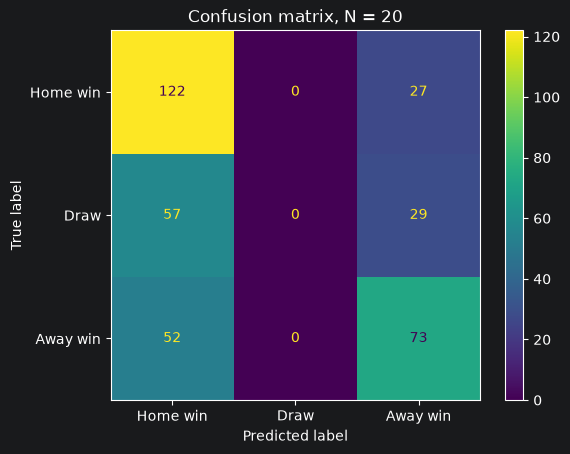

In [12]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=["H", "D", "A"],
    display_labels=["Home win", "Draw", "Away win"]
)
plt.title(f"Confusion matrix, N = {best_n}")
plt.show()


In [13]:
draw_index = list(final_model.classes_).index("D")
test_probabilities = final_model.predict_proba(X_test)
draw_probabilities = test_probabilities[:, draw_index]

real_draws = (y_test == "D").to_numpy()
not_draws = ~real_draws

print("Средняя вероятность ничьей:")
print("Реальные ничьи:", draw_probabilities[real_draws].mean())
print("Матчи без ничьей:", draw_probabilities[not_draws].mean())

Средняя вероятность ничьей:
Реальные ничьи: 0.22744559986861745
Матчи без ничьей: 0.22731191946026705


### Анализ вероятностей ничейного исхода

Средняя вероятность ничьей практически не отличается для двух групп матчей: **0,2273** для матчей, закончившихся вничью, и **0,2274** для матчей с победителем. Модель не смогла выделить ничейные матчи среди остальных.

Проблема прогнозирования ничьих отмечается и в других исследованиях футбольных матчей: модели часто хуже распознают ничьи, чем победы команд.

**Вывод:** используемые признаки недостаточно информативны для распознавания ничейных исходов.

## 12. Итоговые выводы

В эксперименте сравнивались Baseline и Logistic Regression для пяти значений исторического окна: N = 3, 5, 10, 15 и 20.

1. Наилучший результат на Validation показала Logistic Regression при **N = 20**: Accuracy = **0,5722**, Macro F1 = **0,4175**.
2. Logistic Regression превзошла Baseline по Accuracy и Macro F1 для всех рассмотренных значений N.
3. На независимой тестовой выборке при N = 20 получены Accuracy = **0,5417** и Macro F1 = **0,4056**. Качество немного ниже валидационного, но резкого падения метрик не наблюдается.
4. По отчёту классификации и матрице ошибок модель лучше распознаёт победы домашних команд, хуже — победы гостевых команд, а ничьи не распознаёт вовсе.
5. Дополнительный анализ вероятностей показал, что средняя вероятность ничьей практически одинакова для реальных ничьих и матчей с победителем . Это указывает на то, что текущие признаки почти не помогают отделять ничейные исходы от двух остальных классов.

Таким образом, выбранные признаки содержат информацию, полезную для прогнозирования побед, однако их недостаточно для качественного распознавания всех трёх исходов. Основное ограничение модели — прогнозирование ничьих. Для дальнейшего улучшения эксперимента можно добавить признаки результативности команд: забитые и пропущенные голы, среднюю результативность, разницу голов, а также отдельные показатели игры дома и в гостях.
